## PCA and Text Analysis

This assignment involves processing real e-mails, some of which are scams. 

(Fair warning: Some of these scam e-mails have offensive content. If you start reading the e-mail text or the token data, you might read something offensive. If that's a problem, feel free to e-mail us, and we can talk about it and discuss how to proceed with alternative tasks.)

**Q1.**

**Tokens**: The individual words or symbols that create text data like emails. Natural Language Processing is primarily about analyzing the frequency and co-occurrence of tokens.

We aggregated all the emails into a single vector, and removed the punctuation and very common words (e.g. "the"). Run the below code chunk to open it, and use the Counter class to look at the most common words:

In [27]:
import pickle

with open('data/all_tokens.pickle', 'rb') as file:
    all_tokens = pickle.load(file)
    
from collections import Counter
token_count = Counter(all_tokens)
token_freq = token_count.most_common()

Plot a histogram of the occurrences of tokens. 
What do you notice about the frequency of occurrence of different tokens? How does it look?

**Q2.** 

Load `Phishing_clean.parquet`. This is the text from the e-mails broken into the most common 2,711 tokens and one-hot-encoded as features/covariates. So each row is an e-mail, the `Email Type` takes the value 1 if it's a scam and 0 otherwise, and every other column is a word or symbol that occurs in at least 15 e-mails.

1. Perform an 80/20 train-test split of the data.
2. Run a regression of $y$ on the one-hot-encoded emails. What is the $R^2$ on the test set? On the training set?
3. What words have the largest coefficients in absolute value and most strongly influence predictions? 

**Q3.** 

Take the matrix of one-hot-encoded tokens (the data, less the outcome variable, `Email Type`) and perform a principal components analysis decomposition with two components. Plot the first two principal components in a scatter plot, and hue the points by whether they are a phishing scam or not. Do you notice any patterns?

**Q4.**

Run a linear regression of $y$ on the first 2,610 principal components of $X$. What is the $R^2$ on the training and test sets?
How does this performance compare to the linear regression?

**Q5.**

Explain briefly in your own words what the advantage is in using the principal components to run this high-dimensional regression, rather than the original data.

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** Andrew Nguyen

**Date:** 10-21-26

**Q1.**

**Tokens**: The individual words or symbols that create text data like emails. Natural Language Processing is primarily about analyzing the frequency and co-occurrence of tokens.

We aggregated all the emails into a single vector, and removed the punctuation and very common words (e.g. "the"). Run the below code chunk to open it, and use the Counter class to look at the most common words:
Plot a histogram of the occurrences of tokens. 
What do you notice about the frequency of occurrence of different tokens? How does it look?

---
The histogram is heavily right skewed. Most tokens appear only a few times, while less occur very frequently, creating a tail. 

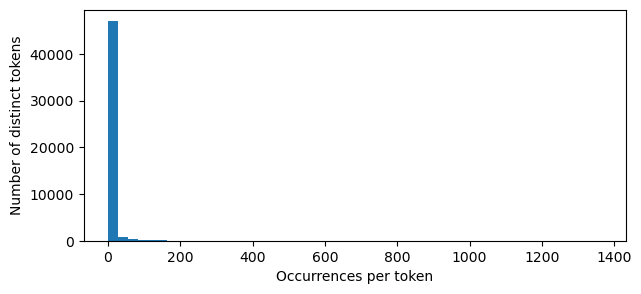

In [28]:
counts = list(token_count.values())

import matplotlib.pyplot as plt

plt.figure(figsize=(7, 3))
plt.hist(counts, bins=50)
plt.xlabel("Occurrences per token")
plt.ylabel("Number of distinct tokens")
plt.show()

**Q2.** 

Load `Phishing_clean.parquet`. This is the text from the e-mails broken into the most common 2,711 tokens and one-hot-encoded as features/covariates. So each row is an e-mail, the `Email Type` takes the value 1 if it's a scam and 0 otherwise, and every other column is a word or symbol that occurs in at least 15 e-mails.

1. Perform an 80/20 train-test split of the data.
2. Run a regression of $y$ on the one-hot-encoded emails. What is the $R^2$ on the test set? On the training set?
3. What words have the largest coefficients in absolute value and most strongly influence predictions? 

---
The $R^2$ on the test set was -7.57 x $10^23$, which indicated extremely poor generalization. The training $R^2$ value was 0.7663, so the model explained about 76.63% of the training outcome variation.

The largest absolute coefficients were "reserved," the image-URL token, "underline,", "iit," and "demokritos."  

In [29]:
import pandas as pd

emails = pd.read_parquet("data/Phishing_clean.parquet")

X = emails.drop(columns=["Email Type"])
y = emails["Email Type"]

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

from sklearn.linear_model import LinearRegression

fit = LinearRegression().fit(X_train, y_train)

print("Training R²:", fit.score(X_train, y_train))
print("Test R²:", fit.score(X_test, y_test))

coefficients = pd.Series(fit.coef_, index=X.columns)

largest = coefficients.abs().sort_values(ascending=False).head(10)
print(coefficients.loc[largest.index])

Training R²: 0.7662702774771087
Test R²: -7.57402933885971e+23
reserved.                                                        -2.377168e+13
url(http://images.lockergnome.com/images/issue/top-right.gif);   -1.485430e+13
underline;                                                        1.485430e+13
iit                                                               1.053085e+13
demokritos                                                       -1.053085e+13
400                                                               1.035349e+13
-0700                                                            -1.030949e+13
pudge.                                                            1.009209e+13
800                                                               1.000509e+13
1997                                                             -9.473526e+12
dtype: float64


In [30]:
print("Number of features:", X_train.shape[1])
print("Matrix rank:", fit.rank_)
print("Smallest singular values:", fit.singular_[-5:])
print("Test prediction range:",
      fit.predict(X_test).min(),
      fit.predict(X_test).max())

Number of features: 2711
Matrix rank: 2649
Smallest singular values: [2.19242285e-15 2.10843945e-15 2.03059502e-15 1.93429218e-15
 1.73267971e-15]
Test prediction range: -23771675583752.293 7004991924864.075


**Q3.** 

Take the matrix of one-hot-encoded tokens (the data, less the outcome variable, `Email Type`) and perform a principal components analysis decomposition with two components. Plot the first two principal components in a scatter plot, and hue the points by whether they are a phishing scam or not. Do you notice any patterns?

---
I noticed that the scam and non scam emaiks overlap a lot, especially in the main cluster. However, the groups in the larger PC1 values are mostly non-scam, while scam emails tend to have higher PC2 values within the main cluster. These patterns are still very small, and I do not see them clearly separating the two email types.

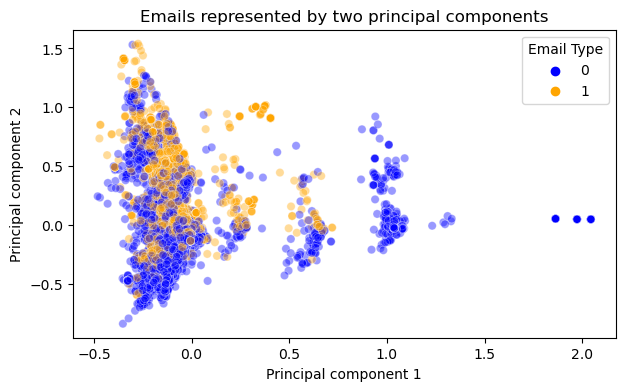

In [31]:
from sklearn.decomposition import PCA
import seaborn as sns
import matplotlib.pyplot as plt

pca = PCA(n_components=2)
components = pca.fit_transform(X)

plt.figure(figsize=(7, 4))
sns.scatterplot(
    x=components[:, 0],
    y=components[:, 1],
    hue=y,
    palette={0: "blue", 1: "orange"}, #blue is non scam orange is scam
    alpha=0.4
)
plt.xlabel("Principal component 1")
plt.ylabel("Principal component 2")
plt.title("Emails represented by two principal components")
plt.show()

**Q4.**

Run a linear regression of $y$ on the first 2,610 principal components of $X$. What is the $R^2$ on the training and test sets?
How does this performance compare to the linear regression?

---
The R squared for training data was 0.7662, and the test R squared was 0.6683. The training performance was nearly identical to the original regressio, but the test performance improved by a lot.

In [32]:
pca_reg = PCA(n_components=2610)

X_train_pca = pca_reg.fit_transform(X_train)
X_test_pca = pca_reg.transform(X_test)

pca_fit = LinearRegression().fit(X_train_pca, y_train)

R2_train = pca_fit.score(X_train_pca, y_train)
R2_test = pca_fit.score(X_test_pca, y_test)

print("R squared for training data:", R2_train)
print("R squared for testing data:", R2_test)

R squared for training data: 0.7662326827745852
R squared for testing data: 0.6683390643101161


**Q5.**

Explain briefly in your own words what the advantage is in using the principal components to run this high-dimensional regression, rather than the original data.

---
PCA combines overlapping information from many features into components. Keeping fewer components can remove redundant or unstable directions, and also can help us better understand the data. Removing the unstable directions can make the regression predictions more reliable on unseen data. 

## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** [To be provided]
- **AI tool and model used:** [To be provided]

### *Prompts used

1. [Paste prompt]
2. [Paste follow-up prompt]

### *AI-proposed changes


[Paste the AI's concise numbered list verbatim.]

1. ...
2. ...

### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1 | Accept / modify / reject | ... |
| 2 | Accept / modify / reject | ... |

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

In [33]:
# Your Phase 2 solution to the problem goes here.


### *Reflection on AI assistance
In your own words without generative AI.

[In 150–300 words, describe the main improvements, AI mistakes or limitations, how the final solution was verified, and any remaining concerns.]